# Actividad post-clase: SVM con sintonización de parámetros
**EST852 Machine Learning · Support Vector Machines**

**Tiempo estimado:** 60–90 minutos · **Modalidad:** individual o en parejas · **Entrega:** este cuaderno ejecutado de principio a fin, con tus respuestas escritas (fecha: *por definir en el curso*).

## Qué vas a hacer
Aplicarás una SVM a un problema **distinto** al de la clase: reconocer dígitos escritos a mano (`load_digits`: 1797 imágenes de 8×8 píxeles, 10 clases). Seguirás el flujo completo de un análisis:

| Paso | Qué haces |
|---|---|
| 1 | Explorar los datos |
| 2 | Particionar y fijar una línea base |
| 3 | Ajustar una SVM con parámetros por defecto |
| 4 | Decidir si conviene estandarizar |
| 5 | Comparar kernels con validación cruzada |
| 6 | Sintonizar **C** (kernel lineal) |
| 7 | Sintonizar **C y gamma** (kernel RBF) |
| 8 | Evaluar el modelo final, **una sola vez** |
| 9 | Reflexionar |
| 10 | Reto opcional |

## Cómo trabajar
- Cada paso trae un **Enunciado**, una **Predicción** (anótala *antes* de ejecutar), la **celda para completar** (`...`) y una celda de **verificación** que te dice si tu resultado coincide con el esperado.
- Reemplaza los `...` por tu código. No cambies las celdas marcadas **[DADO]**.
- Las verificaciones usan `random_state=0` en todas partes; si cambias semillas, no coincidirán.

## Reglas del juego (las mismas de la clase)
1. El conjunto de **prueba** se usa **una sola vez**, al final (paso 8). Todo lo demás se decide con validación cruzada sobre el entrenamiento.
2. Si usas un preprocesamiento, va **dentro de un `Pipeline`**.
3. Compara siempre contra la **línea base** y contra un modelo simple.

## Pauta de evaluación (10 puntos)
| Criterio | Puntos |
|---|---|
| Pasos 1–3 ejecutan y pasan la verificación | 2 |
| Pasos 4–5 (comparaciones con CV, sin usar el conjunto de prueba) | 2 |
| Pasos 6–7 (sintonización correcta con `GridSearchCV`) | 3 |
| Paso 8 (evaluación final única y bien interpretada) | 1 |
| Paso 9 (reflexión argumentada con tus propios resultados) | 2 |
| Reto opcional | +1 de bonificación |

## [DADO] Preparación

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})

def verificar(nombre, obtenido, esperado, tol=5e-4):
    ok = np.allclose(obtenido, esperado, atol=tol)
    print(('✔' if ok else '✘'), nombre, '→', np.round(obtenido, 4), '' if ok else f'(esperado ≈ {esperado})')

# Validación cruzada que usarás en todos los pasos (misma partición para comparar justo)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

## Paso 1. Explorar los datos
**Enunciado.** Cada imagen es una matriz de 8×8 píxeles con intensidades de 0 a 16, aplanada en un vector de 64 variables. Obtén el número de observaciones y de variables, el rango de valores de los píxeles y cuántas imágenes hay de cada dígito.

**Predicción.** ¿Están las 64 variables en la misma escala? ¿Qué crees que pasará con la estandarización en este problema?

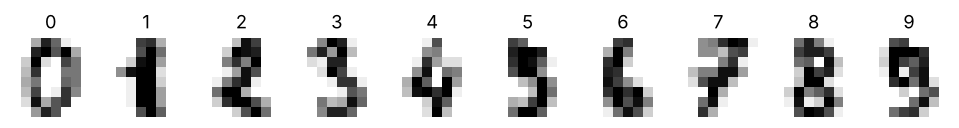

In [2]:
# [DADO] mira algunos dígitos
digitos = load_digits()
fig, ejes = plt.subplots(1, 10, figsize=(11, 1.5))
for ax, img, etiqueta in zip(ejes, digitos.images, digitos.target):
    ax.imshow(img, cmap='gray_r'); ax.set_title(etiqueta); ax.axis('off')
plt.show()

In [3]:
X, y = digitos.data, digitos.target
n, p = X.shape
rango = (X.min(), X.max())
conteo = np.bincount(y)
print(n, p, rango, conteo)

1797 64 (np.float64(0.0), np.float64(16.0)) [178 182 177 183 181 182 181 179 174 180]


In [4]:
verificar('observaciones', n, 1797); verificar('variables', p, 64)
verificar('rango', rango, (0, 16)); verificar('mínimo de imágenes por dígito', conteo.min(), 174)

✔ observaciones → 1797 
✔ variables → 64 
✔ rango → [ 0. 16.] 
✔ mínimo de imágenes por dígito → 174 


## Paso 2. Partición y línea base
**Enunciado.** Separa 70 % para entrenamiento y 30 % para prueba, **estratificado** y con `random_state=0`. Luego calcula la **línea base**: la exactitud en prueba de un modelo que siempre responde la clase más frecuente del entrenamiento.

**Predicción.** Con 10 clases casi balanceadas, ¿qué exactitud tendrá la línea base?

In [5]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=0)
clase_mayor = np.bincount(ytr).argmax()
linea_base = np.mean(yte == clase_mayor)
print(Xtr.shape, Xte.shape, f'línea base = {linea_base:.3f}')

(1257, 64) (540, 64) línea base = 0.102


In [6]:
verificar('n entrenamiento', Xtr.shape[0], 1257); verificar('n prueba', Xte.shape[0], 540)
verificar('línea base', linea_base, 0.1019)

✔ n entrenamiento → 1257 
✔ n prueba → 540 
✔ línea base → 0.1019 


## Paso 3. SVM con parámetros por defecto
**Enunciado.** Ajusta `SVC()` (kernel RBF, `C=1`, `gamma='scale'`) con los datos de entrenamiento. Calcula la exactitud en prueba **solo para esta primera mirada** y cuenta los vectores soporte. Luego calcula tú mismo el valor que `gamma='scale'` usa, con la fórmula de la documentación: `1 / (n_variables * X.var())` sobre el **entrenamiento**.

**Predicción.** ¿Qué fracción de los 1257 puntos de entrenamiento serán vectores soporte: menos del 10 %, alrededor de la mitad o casi todos?

> *Nota: mirar la prueba aquí es solo para tener una referencia. Desde el paso 4 todas las decisiones usan solo validación cruzada.*

In [7]:
svm0 = SVC().fit(Xtr, ytr)
acc0 = svm0.score(Xte, yte)
n_sv0 = svm0.n_support_.sum()
gamma_scale = 1 / (Xtr.shape[1] * Xtr.var())
print(f'exactitud prueba = {acc0:.3f} | vectores soporte = {n_sv0} de {len(ytr)} | gamma_scale = {gamma_scale:.2e}')

exactitud prueba = 0.987 | vectores soporte = 593 de 1257 | gamma_scale = 4.31e-04


In [8]:
verificar('exactitud prueba', acc0, 0.9870); verificar('vectores soporte', n_sv0, 593, tol=0.5)
verificar('gamma_scale', gamma_scale, svm0._gamma, tol=1e-9)

✔ exactitud prueba → 0.987 
✔ vectores soporte → 593 
✔ gamma_scale → 0.0004 


## Paso 4. ¿Conviene estandarizar?
**Enunciado.** Compara, con validación cruzada (`CV`) sobre el **entrenamiento**, el RBF por defecto **sin** estandarizar frente a un `Pipeline` con `StandardScaler` + `SVC()`. Guarda la exactitud media de cada uno.

**Predicción.** En la clase, estandarizar mejoró mucho el RBF. ¿Pasará lo mismo aquí? Piensa en qué unidades están los 64 píxeles.

In [9]:
cv_sin = cross_val_score(SVC(), Xtr, ytr, cv=CV).mean()
cv_con = cross_val_score(make_pipeline(StandardScaler(), SVC()), Xtr, ytr, cv=CV).mean()
print(f'sin estandarizar: {cv_sin:.3f} | con estandarizar: {cv_con:.3f}')

sin estandarizar: 0.986 | con estandarizar: 0.977


In [10]:
verificar('CV sin estandarizar', cv_sin, 0.9857); verificar('CV con estandarizar', cv_con, 0.9769)

✔ CV sin estandarizar → 0.9857 
✔ CV con estandarizar → 0.9769 


**Tu respuesta (paso 4: ¿mejoró o empeoró estandarizar? ¿Por qué crees que ocurrió, comparado con la clase?):** 
> *(escribe aquí, 2–4 líneas)*

## Paso 5. Comparar kernels
**Enunciado.** Con los datos **sin estandarizar** (decisión del paso 4), calcula la exactitud media en validación cruzada de tres SVM con kernel `'linear'`, `'rbf'` y `'poly'` (parámetros por defecto). Guarda los resultados en un diccionario.

**Predicción.** ¿Cuál kernel crees que gana? ¿Y cuál será el más costoso en número de vectores soporte?

In [11]:
cv_kernels = {k: cross_val_score(SVC(kernel=k), Xtr, ytr, cv=CV).mean() for k in ['linear', 'rbf', 'poly']}
print(pd.Series(cv_kernels).round(3))

linear    0.973
rbf       0.986
poly      0.984
dtype: float64


In [12]:
verificar('lineal', cv_kernels['linear'], 0.9729); verificar('rbf', cv_kernels['rbf'], 0.9857)
verificar('poly', cv_kernels['poly'], 0.9841)

✔ lineal → 0.973 
✔ rbf → 0.9857 
✔ poly → 0.9841 


**Tu respuesta (paso 5: ¿las diferencias entre kernels son grandes? Considera que la validación cruzada tiene ruido de aproximadamente ±1 punto):** 
> *(escribe aquí, 2–4 líneas)*

## Paso 6. Sintonizar C (kernel lineal)
**Enunciado.** Usa `GridSearchCV` con `SVC(kernel='linear')` y la grilla logarítmica `C ∈ {1e-4, 1e-3, 1e-2, 1e-1, 1, 10}`, con `cv=CV`. Guarda el mejor `C` y la exactitud CV de cada valor. Luego grafica la curva (la celda de gráfico es dada).

**Predicción.** ¿Qué pasa con la exactitud si C es muy pequeño? ¿Y si es muy grande? ¿Dónde esperas la meseta?

> *Recuerda: en scikit-learn, C grande penaliza más las violaciones del margen (convención opuesta a ISL).*

In [13]:
Cs = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
busca_lin = GridSearchCV(SVC(kernel='linear'), {'C': Cs}, cv=CV).fit(Xtr, ytr)
mejor_C_lin = busca_lin.best_params_['C']
curva_lin = busca_lin.cv_results_['mean_test_score']
print('mejor C:', mejor_C_lin, '| CV =', round(busca_lin.best_score_, 3))

mejor C: 0.001 | CV = 0.979


✔ exactitud CV con C=1e-4 → 0.9539 
✔ mejor exactitud CV (lineal) → 0.9785 


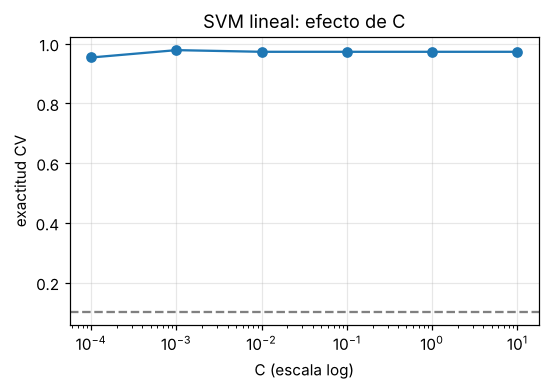

In [14]:
verificar('exactitud CV con C=1e-4', curva_lin[0], 0.9539); verificar('mejor exactitud CV (lineal)', busca_lin.best_score_, 0.9785)
plt.figure(figsize=(5.5, 3.4)); plt.semilogx(Cs, curva_lin, 'o-'); plt.axhline(linea_base, ls='--', c='gray')
plt.xlabel('C (escala log)'); plt.ylabel('exactitud CV'); plt.title('SVM lineal: efecto de C'); plt.grid(alpha=.3); plt.show()

**Tu respuesta (paso 6: describe la forma de la curva y explica por qué C muy pequeño rinde menos):** 
> *(escribe aquí, 2–4 líneas)*

## Paso 7. Sintonizar C y gamma (kernel RBF)
**Enunciado.** Usa `GridSearchCV` con `SVC(kernel='rbf')` y la grilla `C ∈ {0.1, 1, 10, 100}` × `gamma ∈ {3e-4, 1e-3, 3e-3, 1e-2}` con `cv=CV`. Guarda el mejor par de parámetros y arma la tabla 4×4 de exactitudes (la celda del mapa de calor es dada). Luego **ajusta un modelo final** con los mejores parámetros usando todo el entrenamiento (si usas `GridSearchCV` con `refit=True`, ya queda en `busca_rbf.best_estimator_`).

**Predicción.** ¿En qué esquina de la grilla esperas el peor resultado? ¿Qué rol cumple el valor `gamma_scale` que calculaste en el paso 3?

In [15]:
grilla = {'C': [0.1, 1, 10, 100], 'gamma': [3e-4, 1e-3, 3e-3, 1e-2]}
busca_rbf = GridSearchCV(SVC(kernel='rbf'), grilla, cv=CV).fit(Xtr, ytr)
mejores = busca_rbf.best_params_
tabla = pd.DataFrame(busca_rbf.cv_results_['mean_test_score'].reshape(4, 4),
                     index=grilla['C'], columns=grilla['gamma'])
modelo_final = busca_rbf.best_estimator_
print(mejores, '| CV =', round(busca_rbf.best_score_, 3))

{'C': 1, 'gamma': 0.001} | CV = 0.986


✔ mejor exactitud CV (RBF) → 0.9865 
✔ exactitud CV en la esquina C=0.1, gamma=1e-2 → 0.1782 


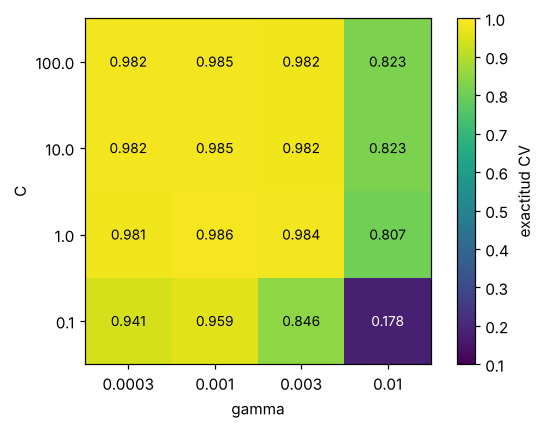

In [16]:
verificar('mejor exactitud CV (RBF)', busca_rbf.best_score_, 0.9865)
verificar('exactitud CV en la esquina C=0.1, gamma=1e-2', tabla.iloc[0, 3], 0.1782)
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(tabla.values, cmap='viridis', origin='lower', vmin=0.1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(tabla.columns); ax.set_yticks(range(4)); ax.set_yticklabels(tabla.index)
ax.set_xlabel('gamma'); ax.set_ylabel('C')
for (i, j), v in np.ndenumerate(tabla.values):
    ax.text(j, i, f'{v:.3f}', ha='center', va='center', color='w' if v < .8 else 'k', fontsize=9)
plt.colorbar(im, label='exactitud CV'); plt.tight_layout(); plt.show()

**Tu respuesta (paso 7: ¿qué ocurre con gamma grande y por qué? ¿Cuántos valores de la grilla superan al kernel lineal del paso 6?):** 
> *(escribe aquí, 2–4 líneas)*

## Paso 8. Evaluación final (una sola vez)
**Enunciado.** Con `modelo_final`, calcula la exactitud en el conjunto de prueba y la matriz de confusión. Determina qué par de dígitos se confunde más (el mayor valor **fuera de la diagonal**) y cuántos vectores soporte tiene el modelo.

**Predicción.** ¿Qué dígitos crees que se confundirán más entre sí?

In [17]:
pred = modelo_final.predict(Xte)
acc_final = np.mean(pred == yte)
mc = confusion_matrix(yte, pred)
fuera = mc.copy(); np.fill_diagonal(fuera, 0)
real, predicho = np.unravel_index(fuera.argmax(), fuera.shape)
n_sv_final = modelo_final.n_support_.sum()
print(f'exactitud prueba = {acc_final:.3f} | par más confundido: real {real} → predicho {predicho} ({fuera.max()} casos) | SV = {n_sv_final}')

exactitud prueba = 0.993 | par más confundido: real 8 → predicho 1 (2 casos) | SV = 643


✔ exactitud final en prueba → 0.9926 
✔ vectores soporte → 643 


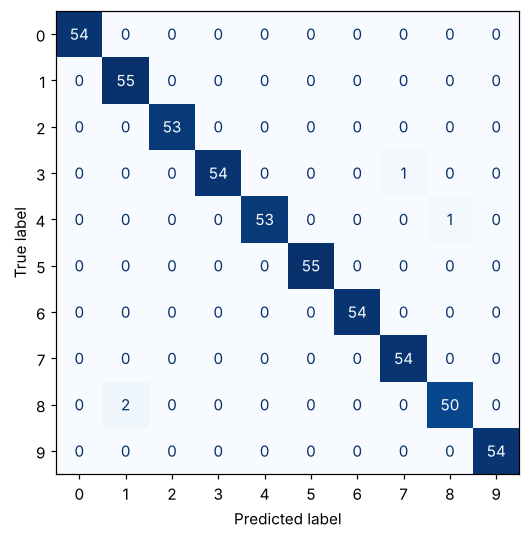

In [18]:
verificar('exactitud final en prueba', acc_final, 0.9926); verificar('vectores soporte', n_sv_final, 643, tol=0.5)
fig, ax = plt.subplots(figsize=(5.4, 5))
ConfusionMatrixDisplay(mc).plot(ax=ax, colorbar=False, cmap='Blues'); plt.tight_layout(); plt.show()

**Tu respuesta (paso 8: compara tu exactitud final con la línea base y con la del paso 3. ¿Cuántas imágenes de diferencia hay? ¿Es una mejora que confirmarías con más datos?):** 
> *(escribe aquí, 2–4 líneas)*

## Paso 9. Reflexión final
Responde con tus propias palabras y **apoyándote en los números que obtuviste**:

1. En este problema, ¿estandarizar ayudó o no? ¿Qué característica de los datos lo explica? ¿Cambia tu regla de "estandarizar siempre"?
2. Para tu modelo final, ¿qué fracción del entrenamiento son vectores soporte? ¿Qué implica esto para el costo de predecir y para la cota de generalización vista en clase?
3. ¿Por qué la grilla de `gamma` debe ser logarítmica y por qué no se puede sintonizar `C` independientemente de `gamma`?
4. ¿Por qué no usaste el conjunto de prueba para elegir entre el kernel lineal y el RBF?
5. Si tu exactitud en prueba (paso 8) es mayor que la exactitud CV del mejor modelo, ¿significa que el modelo generaliza mejor de lo esperado? Explica la cautela necesaria.

**Tu respuesta (9.1):** 
> *(escribe aquí, 2–4 líneas)*

**Tu respuesta (9.2):** 
> *(escribe aquí, 2–4 líneas)*

**Tu respuesta (9.3):** 
> *(escribe aquí, 2–4 líneas)*

**Tu respuesta (9.4):** 
> *(escribe aquí, 2–4 líneas)*

**Tu respuesta (9.5):** 
> *(escribe aquí, 2–4 líneas)*

## Paso 10. Reto opcional (+1 punto): ¿la mejora de sintonizar es real?
**Enunciado.** Un solo conjunto de prueba puede engañar. Repite 10 veces (semillas 0 a 9): (a) partir 70/30 estratificado con esa semilla, (b) ajustar `SVC()` por defecto y medir su exactitud en prueba, (c) sintonizar con `GridSearchCV` (grilla pequeña: `C ∈ {1, 10}`, `gamma ∈ {3e-4, 1e-3, 3e-3}`, validación cruzada con esa semilla) **solo con el entrenamiento** y medir su exactitud en prueba. Informa la diferencia media (sintonizado − por defecto), su desviación estándar y en cuántas particiones gana el sintonizado.

**Predicción.** ¿Sintonizar mejora siempre? ¿Cuánto en promedio?

In [19]:
grilla_chica = {'C': [1, 10], 'gamma': [3e-4, 1e-3, 3e-3]}
acc_def, acc_sint = [], []
for s in range(10):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=s)
    acc_def.append(SVC().fit(a_tr, b_tr).score(a_te, b_te))
    g = GridSearchCV(SVC(), grilla_chica, cv=StratifiedKFold(5, shuffle=True, random_state=s)).fit(a_tr, b_tr)
    acc_sint.append(g.score(a_te, b_te))
dif = np.array(acc_sint) - np.array(acc_def)
print(f'por defecto {np.mean(acc_def):.4f} | sintonizado {np.mean(acc_sint):.4f} | diferencia {dif.mean():.4f} ± {dif.std():.4f} | gana en {(dif > 0).sum()} de 10')

por defecto 0.9863 | sintonizado 0.9900 | diferencia 0.0037 ± 0.0023 | gana en 9 de 10


**Tu respuesta (el reto: ¿la mejora es relevante en la práctica? ¿Qué error habrías cometido si hubieras elegido los parámetros mirando el conjunto de prueba?):** 
> *(escribe aquí, 2–4 líneas)*

---
# PAUTA DEL DOCENTE (solo en la versión con solución)

**Resultados de referencia** (todos con `random_state=0`, scikit-learn 1.9.1): línea base 0,102; SVC por defecto 0,987 en prueba con 593 vectores soporte; CV sin estandarizar 0,986 (0,9857) vs con estandarizar 0,977; kernels lineal 0,973 / RBF 0,986 / poly 0,984; lineal sintonizado C=0,001 con CV 0,979; RBF sintonizado C=1, gamma=0,001 con CV 0,9865; evaluación final 0,993 con 643 vectores soporte (≈51 % del entrenamiento).

| Paso | Respuesta esperada |
|---|---|
| 4 | Estandarizar **empeora** levemente (0,986 → 0,977). Los 64 píxeles ya comparten unidad y escala (0–16); estandarizar amplifica píxeles casi constantes (bordes) que son ruido. La regla "estandarizar siempre" debe matizarse: es prácticamente obligatoria cuando las variables tienen unidades distintas (breast cancer) y no necesariamente cuando comparten escala. Verificarlo con CV. |
| 5 | Lineal 0,973 frente a RBF 0,986 y poly 0,984: las diferencias son de 1 punto o menos y del orden del ruido de la CV. No es una evidencia fuerte de que RBF sea mejor que poly. |
| 6 | Curva: sube de 0,955 (C=1e-4) a ≈0,979 en C=1e-3 y luego queda estable en 0,973: meseta. Con C muy pequeño se penalizan poco las violaciones, el margen es demasiado ancho y el modelo subajusta. Desde C≈1e-3 la exactitud CV ya no cambia de forma relevante (meseta); no se explica aquí por qué, y no hace falta. |
| 7 | Gamma grande (1e-2) colapsa: con C=0,1 la exactitud CV es 0,178 y con C≥1 queda en ≈0,81–0,82; cada punto solo influye en su vecindad y se memoriza el entrenamiento. gamma_scale (4,3e-4) cae en la zona buena y justifica centrar la grilla ahí. Respecto del lineal (0,979): 9 de las 16 celdas lo igualan o superan (C≥1 con gamma ≤ 3e-3, valores 0,981–0,986), así que el RBF sintonizado no es mejor por un margen relevante. |
| 8 | 0,993 en prueba = 4 errores de 540; el modelo por defecto tuvo 0,987 = 7 errores: diferencia de 3 imágenes. Con un solo conjunto de prueba esa diferencia no es concluyente (ver reto). El par más confundido tiene 2 casos (8 clasificado como 1 en esta partición). |
| 9.1 | Ver paso 4. |
| 9.2 | ≈51 % de los puntos son vectores soporte: la cota E[#SV]/m es poco informativa (~0,5 como cota superior), y predecir cuesta O(n_SV · p) por dato. Esto contrasta con breast cancer lineal (7 %). |
| 9.3 | gamma actúa de forma multiplicativa en la distancia, por lo que importan los órdenes de magnitud (de 3e-4 a 1e-2 hay 1,5 órdenes de magnitud y el comportamiento cambia por completo). C y gamma interactúan: con gamma grande, C no puede compensar; con gamma pequeño el modelo es casi lineal y C controla la regularización. |
| 9.4 | Si se usa la prueba para decidir, deja de ser una estimación imparcial del error de generalización (fuga de información, optimismo). |
| 9.5 | No necesariamente: con 540 casos, un error de un par de imágenes mueve ≈0,2–0,4 puntos; la CV sobre el entrenamiento es otra estimación ruidosa; la partición concreta puede ser favorable. Además la CV usada para elegir es optimista para el mejor modelo. |
| Reto | Diferencia media ≈ +0,004 ± 0,002; el sintonizado gana en 9 de 10 particiones: mejora pequeña pero consistente. Elegir parámetros mirando la prueba habría inflado la estimación. |